In [1]:
import time
import os
import pandas as pd
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix


In [2]:
# Load from root data/processed/
train_df = pd.read_csv("../data/processed/train_full.csv")
test_df = pd.read_csv("../data/processed/test_full.csv")

X_train = train_df.drop(columns=["high_sleep_debt"])
y_train = train_df["high_sleep_debt"]
X_test = test_df.drop(columns=["high_sleep_debt"])
y_test = test_df["high_sleep_debt"]

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
os.makedirs("../results", exist_ok=True)



In [3]:
def evaluate_and_save(name, model, param_grid):
    print(f"--- Tuning & Training {name} ---")
    start_time = time.time()
    
    grid = GridSearchCV(model, param_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
    grid.fit(X_train, y_train)
    
    best_model = grid.best_estimator_
    y_pred = best_model.predict(X_test)
    y_prob = best_model.predict_proba(X_test)[:, 1]
    runtime = time.time() - start_time
    
    print(f"Best Params: {grid.best_params_}")
    print(f"Runtime:     {runtime:.2f} sec")
    print(f"Accuracy:    {accuracy_score(y_test, y_pred):.4f}")
    print(f"Precision:   {precision_score(y_test, y_pred):.4f}")
    print(f"Recall:      {recall_score(y_test, y_pred):.4f}")
    print(f"F1-Score:    {f1_score(y_test, y_pred):.4f}")
    print(f"ROC-AUC:     {roc_auc_score(y_test, y_prob):.4f}")
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred), "\n")
    
    # Save predictions for 05_model_comparison.ipynb
    pd.DataFrame({
        "y_true": y_test,
        "y_pred": y_pred,
        "y_prob": y_prob
    }).to_csv(f"../results/{name}_preds.csv", index=False)
    
    return best_model



In [4]:
# 2. Random Forest
rf_grid = {
    "n_estimators": [100, 300],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5]
}
best_rf = evaluate_and_save("RandomForest", RandomForestClassifier(random_state=42), rf_grid)


--- Tuning & Training RandomForest ---
Best Params: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 300}
Runtime:     135.85 sec
Accuracy:    0.8865
Precision:   0.8967
Recall:      0.9168
F1-Score:    0.9066
ROC-AUC:     0.9527
Confusion Matrix:
 [[570 108]
 [ 85 937]] 



In [5]:
# 3. Gradient Boosting
gb_grid = {
    "n_estimators": [100, 300],
    "learning_rate": [0.05, 0.1],
    "max_depth": [3, 5]
}
best_gb = evaluate_and_save("GradientBoosting", GradientBoostingClassifier(random_state=42), gb_grid)

--- Tuning & Training GradientBoosting ---
Best Params: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}
Runtime:     118.38 sec
Accuracy:    0.8847
Precision:   0.8986
Recall:      0.9110
F1-Score:    0.9048
ROC-AUC:     0.9549
Confusion Matrix:
 [[573 105]
 [ 91 931]] 



In [6]:
import matplotlib.pyplot as plt


Top 10 Features — Random Forest:
morning_alarm_snoozes                        0.332803
chronotype_Night Owl                         0.185568
bedtime_phone_minutes                        0.120921
chronotype_Morning Lark                      0.096079
sleep_latency_min                            0.079845
occupation_type_Healthcare / Shift Worker    0.044693
deep_sleep_pct                               0.023207
rem_sleep_pct                                0.020990
screen_brightness_pct                        0.019615
physical_activity_min                        0.019328
dtype: float64 

Top 10 Features — Gradient Boosting:
morning_alarm_snoozes                        0.643038
chronotype_Night Owl                         0.164920
bedtime_phone_minutes                        0.062614
chronotype_Morning Lark                      0.060307
occupation_type_Healthcare / Shift Worker    0.048364
sleep_latency_min                            0.007491
rem_sleep_pct                                0.00

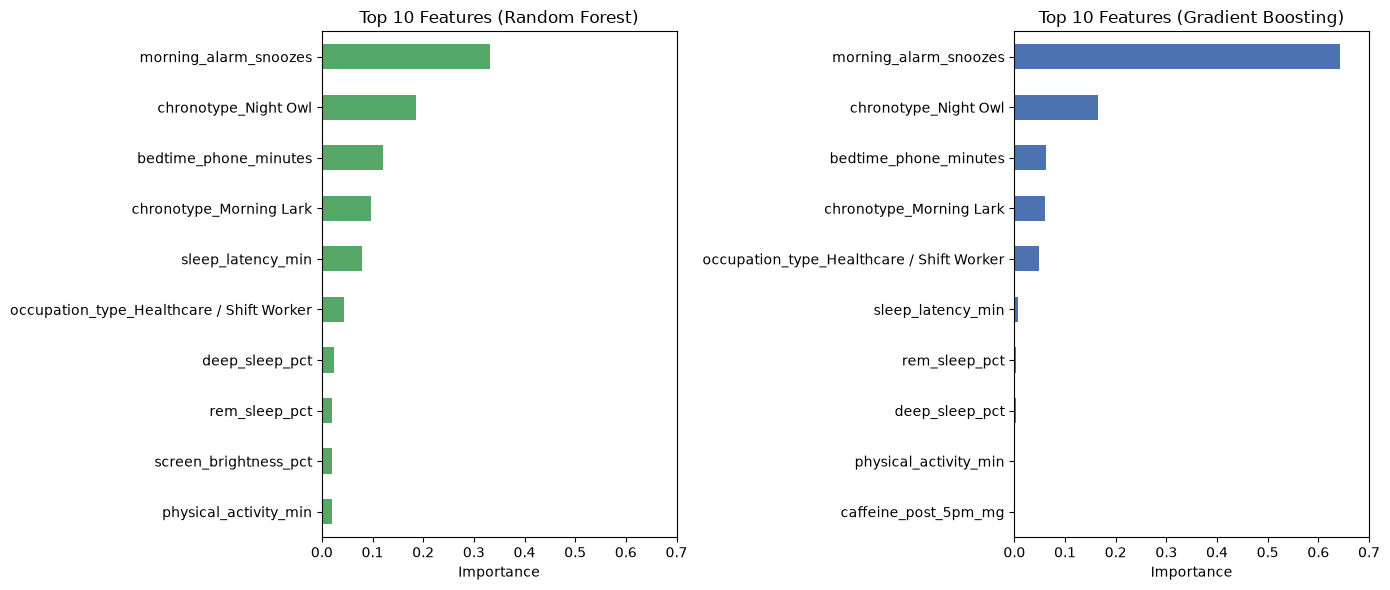

In [8]:
# ==========================================
# 1. FEATURE IMPORTANCES (BOTH MODELS)
# ==========================================
rf_imp = pd.Series(best_rf.feature_importances_, index=X_train.columns).sort_values(ascending=True)
gb_imp = pd.Series(best_gb.feature_importances_, index=X_train.columns).sort_values(ascending=True)

print("Top 10 Features — Random Forest:")
print(rf_imp.tail(10)[::-1], "\n")

print("Top 10 Features — Gradient Boosting:")
print(gb_imp.tail(10)[::-1], "\n")

# Side-by-side plot for the report
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

rf_imp.tail(10).plot(kind="barh", ax=axes[0], color="#55A868", xlim=(0, 0.70))
axes[0].set_title("Top 10 Features (Random Forest)")
axes[0].set_xlabel("Importance")

gb_imp.tail(10).plot(kind="barh", ax=axes[1], color="#4C72B0", xlim=(0, 0.70))
axes[1].set_title("Top 10 Features (Gradient Boosting)")
axes[1].set_xlabel("Importance")

plt.tight_layout()
plt.savefig("../figures/feature_importance_rf_gb.png", dpi=300)
plt.show()



In [9]:
# ==========================================
# 2. BEHAVIORAL-ONLY EVALUATION (BOTH MODELS)
# ==========================================
train_beh = pd.read_csv("../data/processed/train_behavioral_only.csv")
test_beh = pd.read_csv("../data/processed/test_behavioral_only.csv")

X_train_b = train_beh.drop(columns=["high_sleep_debt"])
y_train_b = train_beh["high_sleep_debt"]
X_test_b = test_beh.drop(columns=["high_sleep_debt"])
y_test_b = test_beh["high_sleep_debt"]

for name, best_est in [("RandomForest", best_rf), ("GradientBoosting", best_gb)]:
    # Clone the winning hyperparameters onto a fresh model for the behavioral-only dataset
    beh_model = best_est.__class__(**best_est.get_params())
    beh_model.fit(X_train_b, y_train_b)
    
    y_pred_b = beh_model.predict(X_test_b)
    y_prob_b = beh_model.predict_proba(X_test_b)[:, 1]
    
    print(f"--- {name}: Behavioral-Only (Pre-Sleep Habits Only) ---")
    print(f"Accuracy:  {accuracy_score(y_test_b, y_pred_b):.4f}")
    print(f"Precision: {precision_score(y_test_b, y_pred_b):.4f}")
    print(f"Recall:    {recall_score(y_test_b, y_pred_b):.4f}")
    print(f"F1-Score:  {f1_score(y_test_b, y_pred_b):.4f}")
    print(f"ROC-AUC:   {roc_auc_score(y_test_b, y_prob_b):.4f}\n")
    
    pd.DataFrame({
        "y_true": y_test_b,
        "y_pred": y_pred_b,
        "y_prob": y_prob_b
    }).to_csv(f"../results/{name}_BehavioralOnly_preds.csv", index=False)

--- RandomForest: Behavioral-Only (Pre-Sleep Habits Only) ---
Accuracy:  0.8829
Precision: 0.8930
Recall:    0.9149
F1-Score:  0.9038
ROC-AUC:   0.9541

--- GradientBoosting: Behavioral-Only (Pre-Sleep Habits Only) ---
Accuracy:  0.8847
Precision: 0.8986
Recall:    0.9110
F1-Score:  0.9048
ROC-AUC:   0.9553

